# Задание 4.3
## Бросание монеты до первого герба

### Условие:
«Симметричную» монету бросают до первого появления герба. Найдите вероятность события $A$: будет произведено не более пяти бросаний.

### Вероятностная модель:
Исходы: $\omega_n=\underbrace{TT\dots T}_{n-1}H$ — герб впервые на $n$-м броске, $n=1,2,3,\dots$ (пространство $\Omega=\{\omega_1,\omega_2,\dots\}$ счётно). Так как броски независимы и $p=\tfrac12$,
$$\mathbb P(\omega_n)=\Bigl(\frac12\Bigr)^{n-1}\cdot\frac12=2^{-n},\qquad\sum_{n=1}^\infty2^{-n}=1\ \text{(геометрическая прогрессия)}.$$
### Решение:
$A=\{\omega_1,\dots,\omega_5\}$:
$$\mathbb P(A)=\sum_{n=1}^5 2^{-n}=\frac12+\frac14+\frac18+\frac1{16}+\frac1{32}=\frac{31}{32}=0{,}96875 .$$
Проще через дополнение: $\bar A$ = «первые пять бросков — решки», $\mathbb P(\bar A)=2^{-5}=\frac1{32}$, откуда $\mathbb P(A)=1-\frac1{32}=\frac{31}{32}$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from fractions import Fraction
from math import comb

rng = np.random.default_rng(2024)      # генератор псевдослучайных чисел; фиксированное «зерно» -> результаты воспроизводимы

def running_frequency(hits):
    # Относительная частота p̂_N = N(A)/N для N = 1, 2, ..., len(hits).
    # hits[i] = 1 (True), если в (i+1)-й реализации опыта событие A произошло, иначе 0.
    hits = np.asarray(hits, dtype=float)
    return np.cumsum(hits)/np.arange(1, len(hits) + 1)

def plot_frequency(ax, hits, p_exact, title, label=r'$\hat p_N(A)=N(A)/N$'):
    # График зависимости p̂(A) от числа реализаций N (статистическая устойчивость частоты):
    # синяя линия — относительная частота, красная — точная вероятность,
    # зелёные пунктиры — «коридор» P ± 3·sqrt(P(1−P)/N), в который частота попадает почти всегда.
    n = np.arange(1, len(hits) + 1)
    ph = np.cumsum(hits)/n
    sig = 3*np.sqrt(p_exact*(1 - p_exact)/n)
    ax.plot(n, ph, 'b-', lw=1, label=label)
    ax.axhline(p_exact, color='r', lw=1.5, label=f'P = {p_exact:.6f}')
    ax.plot(n, p_exact + sig, 'g--', lw=0.8, label=r'$P\pm3\sqrt{P(1-P)/N}$'); ax.plot(n, p_exact - sig, 'g--', lw=0.8)
    s = max(10, len(n)//50)                           # первые 2 % точек очень шумные; масштаб по y выбираем по остальным
    lo = min(ph[s:].min(), (p_exact - sig)[s:].min()); hi = max(ph[s:].max(), (p_exact + sig)[s:].max())
    pad = 0.1*(hi - lo); ax.set_ylim(lo - pad, hi + pad)
    ax.set_xlim(0, len(hits)); ax.grid(alpha=0.3); ax.set_xlabel('число реализаций опыта N'); ax.set_ylabel('относительная частота')
    ax.set_title(title, fontsize=10); ax.legend(fontsize=7.5, loc='upper right')

def plot_conditional(ax, hits_AB, hits_B, p_exact, title):
    # График условной частоты p̂(A|B) = N(A∩B)/N(B) в зависимости от общего числа реализаций N
    n = np.arange(1, len(hits_B) + 1); cB = np.cumsum(hits_B); cAB = np.cumsum(hits_AB)
    ph = np.where(cB > 0, cAB/np.maximum(cB, 1), np.nan)
    ax.plot(n, ph, 'b-', lw=1, label=r'$\hat p(A|B)=N(A\cap B)/N(B)$'); ax.axhline(p_exact, color='r', lw=1.5, label=f'значение {p_exact:.5f}')
    s = max(10, len(n)//20); v = ph[s:][~np.isnan(ph[s:])]; lo, hi = min(v.min(), p_exact), max(v.max(), p_exact); pad = 0.15*(hi - lo + 1e-9)
    ax.set_ylim(lo - pad, hi + pad); ax.set_xlim(0, len(hits_B)); ax.grid(alpha=0.3)
    ax.set_xlabel('число реализаций опыта N'); ax.set_ylabel('условная частота'); ax.set_title(title, fontsize=10); ax.legend(fontsize=7.5, loc='upper right')

def table(hits, p_exact, Ns=(100, 1000, 10_000, 100_000, 1_000_000)):
    # Печатает оценки p̂ при разных N, отклонение от точного значения и границу 3σ
    hits = np.asarray(hits, dtype=float)
    print('       N        p̂(N)        |p̂ − P|      3σ_N')
    for N in Ns:
        if N <= len(hits):
            ph = hits[:N].mean(); print(f'{N:9d}   {ph:.7f}   {abs(ph - p_exact):.2e}   {3*np.sqrt(p_exact*(1 - p_exact)/N):.2e}')

In [2]:
# точное значение двумя способами
P_A = sum(Fraction(1, 2**n) for n in range(1, 6)); print('P(A) =', P_A, '=', float(P_A), ';  1 − 2^(−5) =', 1 - Fraction(1, 32))

# моделирование: число бросаний до первого герба имеет геометрическое распределение с p = 1/2
N = 200_000
tosses = rng.geometric(0.5, size=N)                              # номер броска, на котором впервые выпал герб
# для наглядности: «честная» симуляция бросков для первых 20 000 опытов
flips = rng.random((20_000, 40)) < 0.5                            # True = герб
direct = flips.argmax(axis=1) + 1                                 # номер первого герба
print('средняя длина серии (теория 2):', tosses.mean(), ' прямое моделирование:', direct.mean())
hit_A = tosses <= 5
table(hit_A, float(P_A), Ns=(100, 1000, 10_000, 100_000, 200_000))

P(A) = 31/32 = 0.96875 ;  1 − 2^(−5) = 31/32
средняя длина серии (теория 2): 1.99536  прямое моделирование: 2.0022
       N        p̂(N)        |p̂ − P|      3σ_N
      100   0.9800000   1.12e-02   5.22e-02
     1000   0.9710000   2.25e-03   1.65e-02
    10000   0.9702000   1.45e-03   5.22e-03
   100000   0.9691000   3.50e-04   1.65e-03
   200000   0.9688400   9.00e-05   1.17e-03


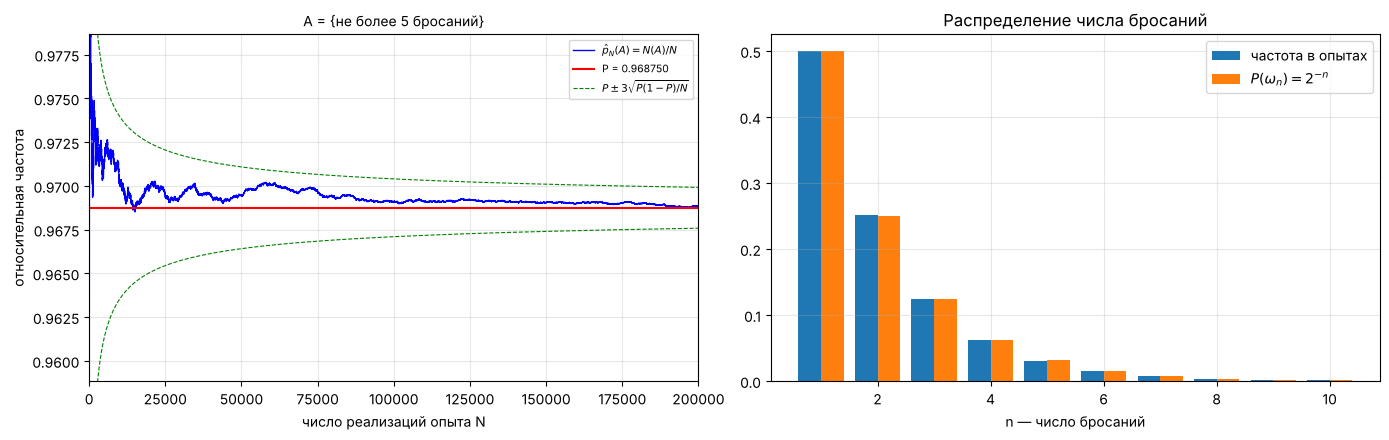

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
plot_frequency(axs[0], hit_A, float(P_A), 'A = {не более 5 бросаний}')
k = np.arange(1, 11); axs[1].bar(k - 0.2, [np.mean(tosses == i) for i in k], 0.4, label='частота в опытах')
axs[1].bar(k + 0.2, 2.0**(-k), 0.4, label='$P(\\omega_n)=2^{-n}$'); axs[1].set_xlabel('n — число бросаний'); axs[1].legend(); axs[1].grid(alpha=0.3)
axs[1].set_title('Распределение числа бросаний')
plt.tight_layout(); plt.savefig('task_4_3.png', dpi=130, bbox_inches='tight'); plt.show()

### Ответ:
$\mathbb P(A)=\dfrac{31}{32}=0{,}96875$.